In [12]:
import numpy as np
import pandas as pd
df= pd.read_csv("raw bank_data.csv")

In [30]:
import csv
with open("raw bank_data.csv", newline="") as f:
    rows = list(csv.reader(f))
header, data = rows[0], rows[1:]
i_inc = header.index("Monthly_Income")
i_bal = header.index("Account_Balance")
i_tr = header.index("Monthly_Transactions")
seen, clean = set(), []
for r in data:
    if tuple(r) not in seen and r[i_inc].strip() not in ("", "Empty") and r[i_bal].strip() not in ("", "Empty"):
        seen.add(tuple(r))
        clean.append(r)
header += ["Balance_to_Income_Ratio", "Transactions_per_Year", "Annual_Income"]
for r in clean:
    inc, bal = float(r[i_inc]), float(r[i_bal])
    tr = float(r[i_tr]) * 12 if r[i_tr].strip() not in ("", "Empty") else "Empty"
    r += [round(bal / inc, 2), tr, inc * 12]
with open(" raw bank_data cleaned.csv", "w", newline="") as f:
    csv.writer(f).writerows([header] + clean)
print("New columns added to bank_data.csv")

New columns added to bank_data.csv


In [ ]:
import csv
import os
cleaned_name = "raw bank_data cleaned.csv"
if not os.path.exists(cleaned_name):
    cleaned_name = " raw bank_data cleaned.csv"
with open(cleaned_name, "r", newline="", encoding="utf-8-sig") as f:
    rows = list(csv.reader(f))
for row in rows[1:]:
    for i in range(len(row)):
        if row[i].strip() == "":
            row[i] = "Empty"
with open("raw bank_data cleaned.csv", "w", newline="") as f:
    csv.writer(f).writerows(rows)
print("Done")

Done


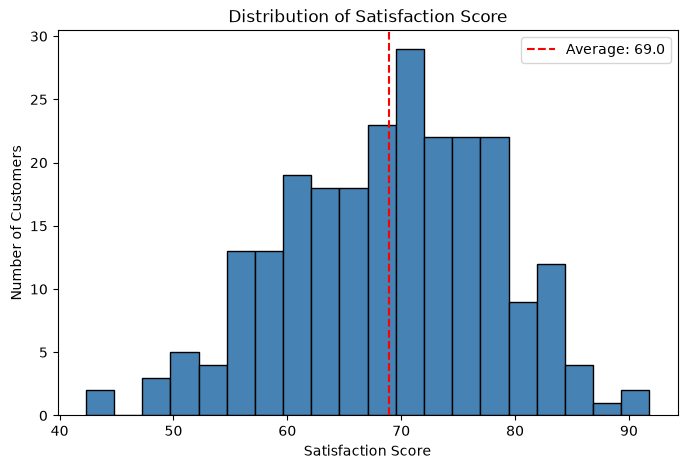

In [6]:
#Q1 What does Satisfaction_Score look like overall?
import pandas as pd
import matplotlib.pyplot as plt
if "df" not in globals():
    df = pd.read_csv("raw bank_data.csv")
avg = df["Satisfaction_Score"].mean()
plt.figure(figsize=(8, 5))
plt.hist(df["Satisfaction_Score"], bins=20, color="steelblue", edgecolor="black")
plt.axvline(avg, color="red", linestyle="--", label="Average: " + str(round(avg, 1)))
plt.title("Distribution of Satisfaction Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("Number of Customers")
plt.legend()
plt.savefig("q1_satisfaction_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


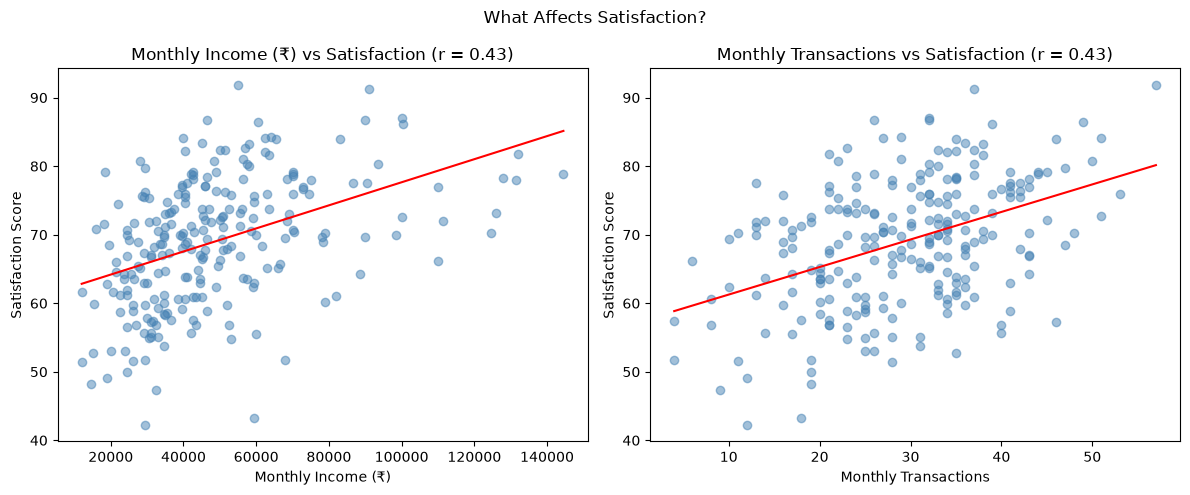

In [15]:
#Q2 Do Monthly_Income and Monthly_Transactions affect Satisfaction_Score?
import matplotlib.pyplot as plt
import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, label in [(axes[0], "Monthly_Income", "Monthly Income (₹)"),
                       (axes[1], "Monthly_Transactions", "Monthly Transactions")]:
    x = df[col]
    y = df["Satisfaction_Score"]
    ax.scatter(x, y, alpha=0.5, color="steelblue")
    slope, intercept = np.polyfit(x, y, 1)
    ax.plot(x.sort_values(), slope * x.sort_values() + intercept, color="red")
    r = x.corr(y)
    ax.set_title(label + " vs Satisfaction (r = " + str(round(r, 2)) + ")")
    ax.set_xlabel(label)
    ax.set_ylabel("Satisfaction Score")
plt.suptitle("What Affects Satisfaction?")
plt.tight_layout()
plt.savefig("q2_income_transactions.png", dpi=150, bbox_inches="tight")
plt.show()

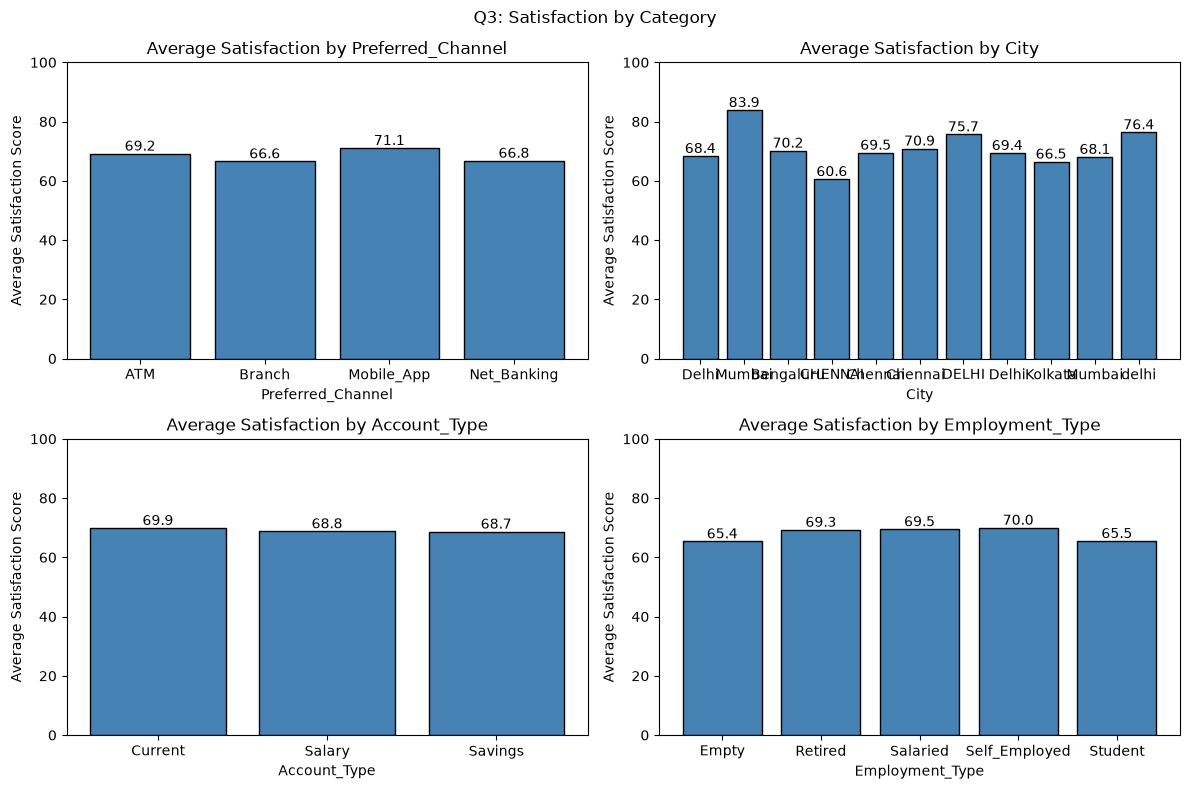

In [16]:
#Q3 Does Satisfaction_Score differ by Preferred_Channel, City, Account_Type and Employment_Type?
import matplotlib.pyplot as plt
cat_cols = ["Preferred_Channel", "City", "Account_Type", "Employment_Type"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    avg = df.groupby(col)["Satisfaction_Score"].mean().round(1)
    ax.bar(avg.index, avg.values, color="steelblue", edgecolor="black")
    ax.set_title("Average Satisfaction by " + col)
    ax.set_xlabel(col)
    ax.set_ylabel("Average Satisfaction Score")
    ax.set_ylim(0, 100)
    for i in range(len(avg)):
        ax.text(i, avg.values[i] + 1, str(avg.values[i]), ha="center")
plt.suptitle("Q3: Satisfaction by Category")
plt.tight_layout()
plt.savefig("q3_satisfaction_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

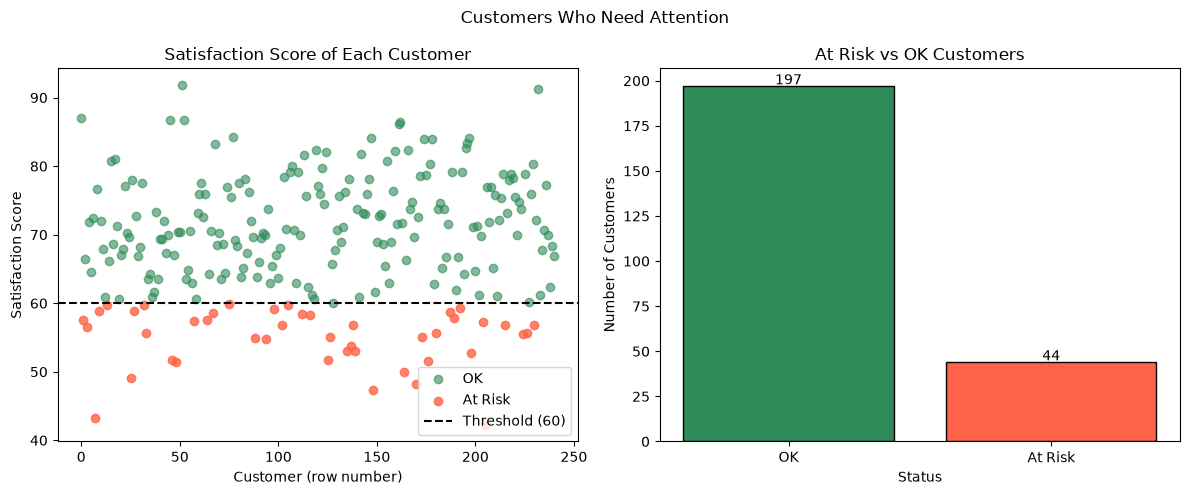

In [18]:
#Q4 Which customers need attention? (score below 60 = At Risk)
import matplotlib.pyplot as plt
df["Status"] = df["Satisfaction_Score"].apply(lambda s: "At Risk" if s < 60 else "OK")
at_risk = df[df["Status"] == "At Risk"]
ok = df[df["Status"] == "OK"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(ok.index, ok["Satisfaction_Score"], color="seagreen", alpha=0.6, label="OK")
axes[0].scatter(at_risk.index, at_risk["Satisfaction_Score"], color="tomato", alpha=0.8, label="At Risk")
axes[0].axhline(60, color="black", linestyle="--", label="Threshold (60)")
axes[0].set_title("Satisfaction Score of Each Customer")
axes[0].set_xlabel("Customer (row number)")
axes[0].set_ylabel("Satisfaction Score")
axes[0].legend()
counts = df["Status"].value_counts()
axes[1].bar(counts.index, counts.values, color=["seagreen" if s == "OK" else "tomato" for s in counts.index],
            edgecolor="black")
axes[1].set_title("At Risk vs OK Customers")
axes[1].set_xlabel("Status")
axes[1].set_ylabel("Number of Customers")
for i in range(len(counts)):
    axes[1].text(i, counts.values[i] + 1, str(counts.values[i]), ha="center")

plt.suptitle("Customers Who Need Attention")
plt.tight_layout()
plt.savefig("q4_at_risk_customers.png", dpi=150, bbox_inches="tight")
plt.show()